# Neural Networks for Classification

In the previous chapter, we saw that a Machine Learning model is a parametric function $f_\Theta: \mathbb{R}^d \to \mathbb{R}^s$, and that linear models are often not expressive enough to describe the relationship between the input and the output. In this chapter, we introduce the most successful family of non-linear models: **Neural Networks**.

There are many ways to introduce Neural Networks. Here, we will follow a *constructive* path: we will start from the problem of **classification**, and we will try to solve it by drawing a graph of very simple computational units. Step by step, we will see that this graph naturally becomes what is known as a **Multi-Layer Perceptron (MLP)**. Finally, we will ask ourselves *how* to choose the parameters of such a network, which will lead us to the definition of the **loss function** and to the computation of its gradient through the **backpropagation** algorithm.

## Classification as drawing boundaries

Consider a binary classification problem with $d = 2$ features, where each datapoint $x = (x_1, x_2) \in \mathbb{R}^2$ belongs to one of two classes, $y \in \{0, 1\}$. As we already discussed, we can visualize such a dataset as a set of points in the plane, colored by their class.

![](./fig/classification1.png)

Solving the classification problem means finding a function $f_\Theta(x)$ that outputs $1$ when $x$ belongs to the red class and $0$ when $x$ belongs to the blue class. Geometrically, this is equivalent to **dividing the plane into two regions**, one for each class. In the example above, it is clear that a **straight line** would do the job.

A straight line in $\mathbb{R}^2$ (or, more generally, a hyperplane in $\mathbb{R}^d$) can be written as

$$
w^T x + b = w_1 x_1 + w_2 x_2 + b = 0,
$$

where $w \in \mathbb{R}^d$ is a vector orthogonal to the line, and $b \in \mathbb{R}$ is a shift. The line divides the space into two **half-planes**: the points where $w^T x + b > 0$ and the points where $w^T x + b < 0$. Therefore, a very natural classifier is

$$
f_\Theta(x) = H(w^T x + b), \qquad
H(t) =
\begin{cases}
1 & \text{if } t \geq 0, \\
0 & \text{if } t < 0,
\end{cases}
$$

where $H(t)$ is the **Heaviside (step) function**, and the parameters of the model are $\Theta = \{ w, b \}$.

![](./fig/classification_2.png)

### A classifier as a graph

Let's look at the classifier above from a different perspective. To compute $f_\Theta(x)$, we:

1. take each input feature $x_j$,
2. multiply it by a **weight** $w_j$,
3. sum all the results together with the **bias** $b$,
4. apply a **threshold** (the function $H$) to decide whether the output is $0$ or $1$.

We can represent this sequence of operations as a **graph**, where each input feature is a node, each weight is an edge, and the sum-and-threshold operation is a new node, which "collects" the information coming from the inputs and "fires" a decision.

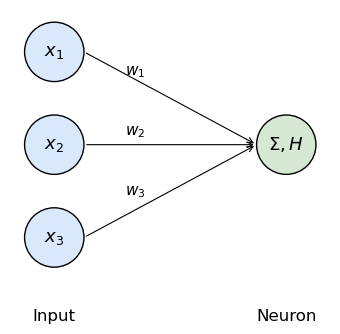

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def draw_network(layer_sizes, layer_labels=None, node_labels=None, edge_labels=None,
                 colors=None, ax=None, figsize=(8, 4)):
    """
    Draws a fully-connected network as a graph.
    layer_sizes: list of the number of nodes in each layer.
    node_labels: list (one per layer) of lists of strings.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    if colors is None:
        colors = ["#dae8fc"] + ["#ffe6cc"] * (len(layer_sizes) - 2) + ["#d5e8d4"]
    pos = []
    for l, n in enumerate(layer_sizes):
        ys = np.linspace(-(n - 1) / 2, (n - 1) / 2, n)[::-1]
        pos.append([(2.5 * l, y) for y in ys])
    # Edges
    for l in range(len(layer_sizes) - 1):
        for i, p in enumerate(pos[l]):
            for j, q in enumerate(pos[l + 1]):
                ax.annotate("", xy=(q[0] - 0.32, q[1]), xytext=(p[0] + 0.32, p[1]),
                            arrowprops=dict(arrowstyle="->", color="k", lw=0.8))
                if edge_labels is not None and edge_labels[l] is not None:
                    t = 0.35
                    ax.text(p[0] + t * (q[0] - p[0]), p[1] + t * (q[1] - p[1]) + 0.1,
                            edge_labels[l][j][i], fontsize=11, ha="center")
    # Nodes
    for l, layer in enumerate(pos):
        for i, (x, y) in enumerate(layer):
            ax.add_patch(plt.Circle((x, y), 0.32, facecolor=colors[l], edgecolor="k", zorder=3))
            if node_labels is not None:
                ax.text(x, y, node_labels[l][i], ha="center", va="center", fontsize=13, zorder=4)
    if layer_labels is not None:
        ymin = min(p[1] for layer in pos for p in layer)
        for l, lab in enumerate(layer_labels):
            ax.text(2.5 * l, ymin - 0.9, lab, ha="center", fontsize=12)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.autoscale_view()
    return ax

draw_network([3, 1],
             layer_labels=["Input", "Neuron"],
             node_labels=[["$x_1$", "$x_2$", "$x_3$"], [r"$\Sigma, H$"]],
             edge_labels=[[["$w_1$", "$w_2$", "$w_3$"]]],
             figsize=(5, 3.5))
plt.show()

This simple computational unit is called an **artificial neuron** (or *perceptron*), and it was introduced by Rosenblatt in 1958, inspired by an earlier model by McCulloch and Pitts (1943). The name comes from a (very rough) analogy with biological neurons: a neuron receives electrical signals from other neurons through its *dendrites*, sums them up and, if the total signal exceeds a certain threshold, it *fires* a signal through its *axon* to the next neurons.

Mathematically, a neuron is just the composition of a linear (more precisely, *affine*) function and a scalar non-linear function $\rho: \mathbb{R} \to \mathbb{R}$, named **activation function**:

$$
\text{neuron}(x) = \rho(w^T x + b).
$$

In our first example, $\rho = H$.

## When one line is not enough

Unfortunately, most of the classification problems we are interested in cannot be solved by a single straight line. Consider for example the following dataset, where the points belonging to class $1$ are the ones *inside* a triangle.

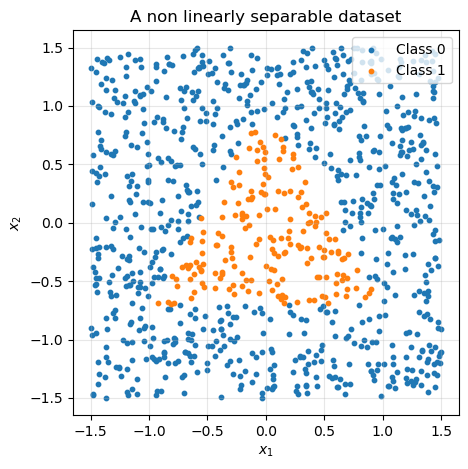

In [2]:
# Generate a dataset of points uniformly distributed in [-1.5, 1.5]^2
np.random.seed(0)
N = 1000
X = np.random.uniform(-1.5, 1.5, (N, 2))

# Class 1 = points inside the triangle with vertices (0, 1), (-1, -0.7), (1, -0.7)
def inside_triangle(X):
    x1, x2 = X[:, 0], X[:, 1]
    return ((x2 + 0.7 >= 0) & (1.7 * x1 - x2 + 1 >= 0) & (-1.7 * x1 - x2 + 1 >= 0)).astype(int)

y = inside_triangle(X)

plt.figure(figsize=(5, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=10, label="Class 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=10, label="Class 1")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("A non linearly separable dataset")
plt.legend(loc="upper right")
plt.gca().set_aspect("equal")
plt.grid(alpha=0.3)
plt.show()

Clearly, there is no straight line separating the two classes. However, note that a point is inside the triangle **if and only if** it lies on the correct side of **all three** lines defining the edges of the triangle. In particular, $x$ is inside the triangle if and only if:

$$
\begin{cases}
x_2 + 0.7 \geq 0 & \text{(above the bottom edge)}, \\
1.7 x_1 - x_2 + 1 \geq 0 & \text{(right of the left edge)}, \\
-1.7 x_1 - x_2 + 1 \geq 0 & \text{(left of the right edge)}.
\end{cases}
$$

Each of these conditions is exactly what a single neuron can check! Therefore, we can use **three neurons**, each of them responsible for one edge of the triangle:

$$
h_j = H(w_j^T x + b_j), \qquad j = 1, 2, 3,
$$

with

$$
w_1 = \begin{bmatrix} 0 \\ 1 \end{bmatrix}, \; b_1 = 0.7, \qquad
w_2 = \begin{bmatrix} 1.7 \\ -1 \end{bmatrix}, \; b_2 = 1, \qquad
w_3 = \begin{bmatrix} -1.7 \\ -1 \end{bmatrix}, \; b_3 = 1.
$$

Then, we need to combine the three answers $h_1, h_2, h_3 \in \{0, 1\}$ into a single decision: the point is inside the triangle if $h_1 = h_2 = h_3 = 1$ (a logical **AND**). But note that the AND of three binary values can be computed by... another neuron! Indeed,

$$
h_1 \text{ AND } h_2 \text{ AND } h_3 = H(h_1 + h_2 + h_3 - 2.5),
$$

since $h_1 + h_2 + h_3 - 2.5 \geq 0$ if and only if all the $h_j$ are equal to $1$. Putting everything together, we obtained a classifier made of **two layers** of neurons:

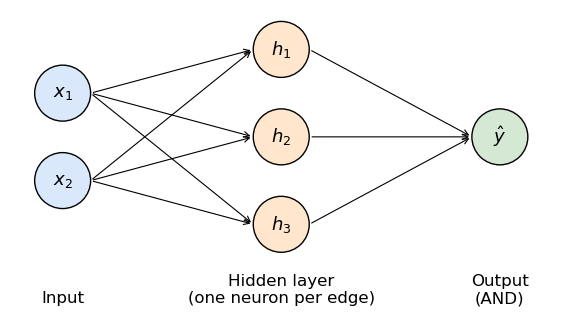

In [3]:
draw_network([2, 3, 1],
             layer_labels=["Input", "Hidden layer\n(one neuron per edge)", "Output\n(AND)"],
             node_labels=[["$x_1$", "$x_2$"], ["$h_1$", "$h_2$", "$h_3$"], ["$\\hat{y}$"]],
             figsize=(7, 4))
plt.show()

Let's implement it, and let's check that it correctly classifies our dataset.

In [4]:
def heaviside(t):
    return (t >= 0).astype(float)

# First layer: one row of W1 for each neuron (i.e. for each edge of the triangle)
W1 = np.array([[0.0, 1.0],
               [1.7, -1.0],
               [-1.7, -1.0]])
b1 = np.array([0.7, 1.0, 1.0])

# Second layer: AND of the three hidden neurons
W2 = np.array([[1.0, 1.0, 1.0]])
b2 = np.array([-2.5])

def hand_made_network(X):
    h = heaviside(X @ W1.T + b1)     # shape (N, 3)
    y_hat = heaviside(h @ W2.T + b2) # shape (N, 1)
    return h, y_hat[:, 0]

h, y_hat = hand_made_network(X)
print(f"Accuracy of the hand-made network: {np.mean(y_hat == y) * 100:.2f}%")

Accuracy of the hand-made network: 100.00%


It works perfectly! To better understand what is going on, let's visualize the region of the plane where each hidden neuron outputs $1$, together with the final output of the network.

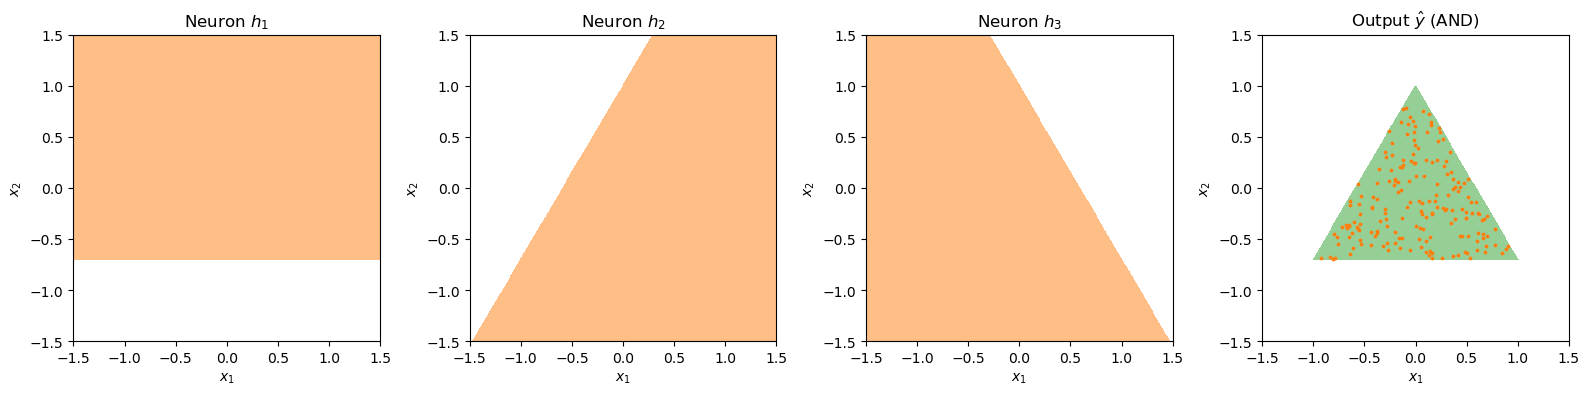

In [5]:
xx1, xx2 = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
grid = np.stack([xx1.ravel(), xx2.ravel()], axis=1)
h_grid, y_grid = hand_made_network(grid)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for j in range(3):
    axes[j].contourf(xx1, xx2, h_grid[:, j].reshape(xx1.shape), levels=[-0.5, 0.5, 1.5],
                     colors=["white", "tab:orange"], alpha=0.5)
    axes[j].set_title(f"Neuron $h_{j+1}$")
axes[3].contourf(xx1, xx2, y_grid.reshape(xx1.shape), levels=[-0.5, 0.5, 1.5],
                 colors=["white", "tab:green"], alpha=0.5)
axes[3].scatter(X[y == 1, 0], X[y == 1, 1], s=3, c="tab:orange")
axes[3].set_title(r"Output $\hat{y}$ (AND)")
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

This simple example contains the fundamental idea of Neural Networks:

> Each neuron solves a **very simple** problem (in our case: "on which side of a line is the point?"). By **composing** many simple neurons in a graph, we can solve **complex** problems.

In particular:

- With $n$ neurons in the hidden layer followed by an AND neuron, we can represent **any convex polygon** with $n$ edges.
- With an additional layer, we can compute the **OR** of multiple polygons (try to write the OR neuron by yourself!), and therefore represent **any union of polygons**, which can approximate any region of the plane as accurately as we want.

This intuition can be made rigorous: it is known as the **Universal Approximation Theorem**, which states (informally) that a Neural Network with at least one hidden layer and enough neurons can approximate any continuous function to an arbitrary accuracy.

> **Exercise:** Design by hand a Neural Network with Heaviside activations solving the **XOR** problem, i.e. classifying as $1$ the points $x \in \mathbb{R}^2$ such that $x_1 x_2 < 0$ (second and fourth quadrant), and as $0$ the others. *Hint:* the XOR can be written as $(A \text{ OR } B) \text{ AND NOT } (A \text{ AND } B)$.

## From hand-made to learned networks

In the previous example, we designed the network **by hand**, choosing the weights by looking at the data. Of course, this is impossible in realistic applications: think of classifying images of $28 \times 28$ pixels, where each datapoint lives in $\mathbb{R}^{784}$, and we do not even know what "the right lines" are.

Therefore, we want the network to **learn** the weights directly from the data. As discussed in the previous chapter, this is done by minimizing a loss function $\mathcal{L}(\Theta)$ which measures how wrong the predictions are. Since we will minimize it with gradient-based algorithms, we need $\mathcal{L}(\Theta)$ to be **differentiable** with respect to $\Theta$.

Here comes the problem: the Heaviside function is constant almost everywhere, and therefore its derivative is $H'(t) = 0$ for any $t \neq 0$ (and it is not defined in $t = 0$). In other words, an infinitesimal change in the weights does not change the output of the network, and the gradient does not give any information on how to improve the weights.

The solution is to replace $H$ with a **smooth** (or at least *almost everywhere differentiable*) activation function, which behaves similarly but has an informative derivative. The most common choices are:

- **Sigmoid**: $\sigma(t) = \frac{1}{1 + e^{-t}}$, a smooth version of the step function, with $\sigma'(t) = \sigma(t)(1 - \sigma(t))$.
- **Hyperbolic tangent**: $\tanh(t) = \frac{e^t - e^{-t}}{e^t + e^{-t}}$, similar to the sigmoid but with values in $(-1, 1)$, with $\tanh'(t) = 1 - \tanh^2(t)$.
- **ReLU** (Rectified Linear Unit): $\mathrm{ReLU}(t) = \max(0, t)$, with $\mathrm{ReLU}'(t) = 1$ if $t > 0$ and $0$ if $t < 0$.

![](./fig/sigmoid.svg)

The ReLU is, by far, the most used activation function in modern Neural Networks for the hidden layers, since it is extremely cheap to compute, and its derivative does not vanish for large positive inputs (contrary to the sigmoid and the tanh, whose derivatives go to zero when $|t| \to \infty$, a phenomenon known as **saturation**).

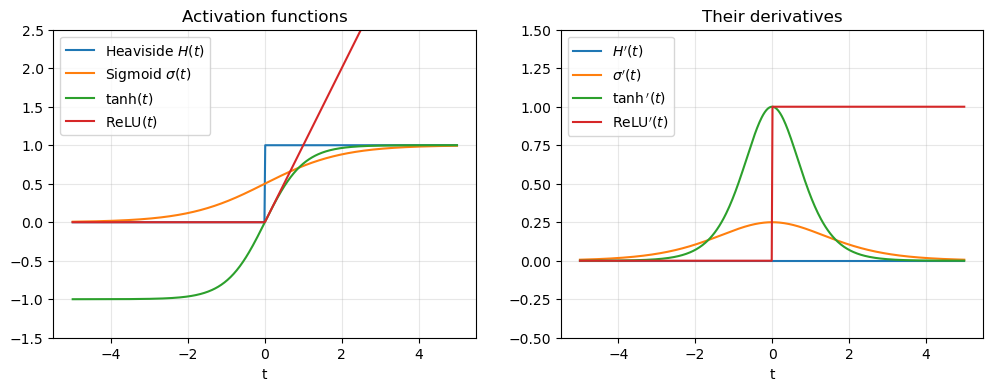

In [6]:
def sigmoid(t):
    return 1 / (1 + np.exp(-t))

def relu(t):
    return np.maximum(0, t)

tt = np.linspace(-5, 5, 500)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tt, heaviside(tt), label="Heaviside $H(t)$")
axes[0].plot(tt, sigmoid(tt), label=r"Sigmoid $\sigma(t)$")
axes[0].plot(tt, np.tanh(tt), label=r"$\tanh(t)$")
axes[0].plot(tt, relu(tt), label=r"ReLU$(t)$")
axes[0].set_ylim(-1.5, 2.5)
axes[0].set_title("Activation functions")

axes[1].plot(tt, np.zeros_like(tt), label="$H'(t)$")
axes[1].plot(tt, sigmoid(tt) * (1 - sigmoid(tt)), label=r"$\sigma'(t)$")
axes[1].plot(tt, 1 - np.tanh(tt)**2, label=r"$\tanh'(t)$")
axes[1].plot(tt, heaviside(tt), label=r"ReLU$'(t)$")
axes[1].set_ylim(-0.5, 1.5)
axes[1].set_title("Their derivatives")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
    ax.set_xlabel("t")
plt.show()

```{note}
A single neuron with sigmoid activation, $f_\Theta(x) = \sigma(w^T x + b)$, is a well-known classifier named **Logistic Regression**. Its output lies in $(0, 1)$ and is interpreted as the probability that $x$ belongs to class $1$, i.e. $f_\Theta(x) = \mathbb{P}(y = 1 \mid x)$. Neural Networks can be thought as many logistic regressions stacked together.
```

## The Multi-Layer Perceptron (MLP)

We are now ready to give the general definition. A **Multi-Layer Perceptron (MLP)** (also called *fully-connected* or *dense* Neural Network) is a function $f_\Theta: \mathbb{R}^d \to \mathbb{R}^s$ obtained by stacking $L$ **layers** of neurons, where each neuron of a layer receives as input the outputs of **all** the neurons of the previous layer.

![](./fig/NN.png)

Let $n_0 = d, n_1, \dots, n_{L-1}, n_L = s$ be the number of neurons in each layer (also called the **width** of the layer). Then, by grouping the weights $w_j$ of all the neurons in the $l$-th layer as the rows of a matrix $W^l \in \mathbb{R}^{n_l \times n_{l-1}}$ and their biases in a vector $b^l \in \mathbb{R}^{n_l}$, the MLP is defined recursively as:

$$
\begin{aligned}
h^0 &= x, \\
z^l &= W^l h^{l-1} + b^l, \qquad &l = 1, \dots, L, \\
h^l &= \rho(z^l), \qquad &l = 1, \dots, L-1, \\
f_\Theta(x) &= z^L,
\end{aligned}
$$

where the activation function $\rho$ is applied **element-wise**. The vectors $z^l$ are called **pre-activations**, while the vectors $h^l$ are called **activations** (or *hidden features*). The layers $1, \dots, L-1$ are named **hidden layers**, while the layer $L$ is the **output layer**. The parameters of the network are

$$
\Theta = \{ W^1, b^1, W^2, b^2, \dots, W^L, b^L \},
$$

and their total number is $\sum_{l=1}^L n_l (n_{l-1} + 1)$.

In other words, an MLP is the **composition** of $L$ affine functions, interleaved by element-wise non-linearities:

$$
f_\Theta(x) = W^L \rho\Big( W^{L-1} \rho\big( \cdots \rho(W^1 x + b^1) \cdots \big) + b^{L-1} \Big) + b^L.
$$

The number of layers $L$ is called the **depth** of the network: when $L$ is large, we talk about **Deep Learning**.

```{warning}
The non-linearity $\rho$ is **fundamental**. Indeed, if $\rho(t) = t$, then the composition of affine functions is again an affine function, and the MLP would collapse into a simple linear model $f_\Theta(x) = Wx + b$, no matter how many layers we use.
```

> **Exercise:** Compute the number of parameters of an MLP with input dimension $d = 784$, two hidden layers with $n_1 = n_2 = 128$ neurons, and output dimension $s = 10$.

### The output layer for classification: the Softmax

For a classification problem with $K$ classes, we set the output dimension to $s = K$, so that the network outputs a vector $z^L \in \mathbb{R}^K$, whose elements are usually called **logits**. As anticipated in the previous chapter, we want to interpret the output of the network as the **probability** of each class. However, the logits are arbitrary real numbers, and therefore they cannot be directly interpreted as probabilities.

To convert them into a probability vector (i.e. a vector with non-negative entries summing up to one), we apply the **Softmax** function:

$$
\hat{y} = \mathrm{softmax}(z^L), \qquad \hat{y}_k = \frac{e^{z^L_k}}{\sum_{j=1}^K e^{z^L_j}}, \quad k = 1, \dots, K.
$$

It is easy to check that $\hat{y}_k \in (0, 1)$ for any $k$ and that $\sum_{k=1}^K \hat{y}_k = 1$. Moreover, the Softmax preserves the ordering of the logits: the largest logit corresponds to the largest probability. Therefore, we interpret

$$
\hat{y}_k = \mathbb{P}(y = k \mid x; \Theta),
$$

and the **predicted class** is the one with the highest probability:

$$
\hat{c}(x) = \arg\max_{k = 1, \dots, K} \hat{y}_k.
$$

```{note}
For $K = 2$, the Softmax reduces to the sigmoid. Indeed, $\hat{y}_1 = \frac{e^{z_1}}{e^{z_1} + e^{z_2}} = \frac{1}{1 + e^{-(z_1 - z_2)}} = \sigma(z_1 - z_2)$.
```

```{warning}
When implementing the Softmax, computing $e^{z_k}$ for large values of $z_k$ easily leads to **overflow**. Since $\mathrm{softmax}(z) = \mathrm{softmax}(z - c)$ for any constant $c \in \mathbb{R}$ (check it!), we always subtract the maximum logit before taking the exponential, i.e. we compute $\mathrm{softmax}(z - \max_j z_j)$.
```

## Training the network: the loss function

We now have a model $f_\Theta(x)$ whose output, after the Softmax, is a probability vector $\hat{y} \in \mathbb{R}^K$. Given a training set $\mathcal{D} = \{ (x^{(i)}, y^{(i)}) \}_{i=1}^N$, where the labels are **one-hot encoded**, i.e. $y^{(i)} = e_{c^{(i)}} \in \mathbb{R}^K$ if $x^{(i)}$ belongs to class $c^{(i)}$, we need to define a loss function measuring how far the predicted probabilities are from the true labels.

The standard choice comes from Statistics, and it is based on the **Maximum Likelihood** principle: we want to choose $\Theta$ such that the probability that the model assigns to the true labels is as large as possible. For a single datapoint $(x, y)$ with $y = e_c$, the probability assigned by the model to the true class is $\hat{y}_c$. Assuming the datapoints are independent, the likelihood of the whole dataset is

$$
\prod_{i=1}^N \hat{y}^{(i)}_{c^{(i)}}.
$$

Maximizing the likelihood is equivalent to minimizing the **negative log-likelihood** (since the logarithm is monotone and it turns products into sums), which, normalized by $N$, reads:

$$
\mathcal{L}(\Theta) = -\frac{1}{N} \sum_{i=1}^N \log \hat{y}^{(i)}_{c^{(i)}} = \frac{1}{N} \sum_{i=1}^N \underbrace{\left( - \sum_{k=1}^K y^{(i)}_k \log \hat{y}^{(i)}_k \right)}_{=: \ell(\Theta; x^{(i)}, y^{(i)})},
$$

where we used that $y^{(i)}_k = 1$ if $k = c^{(i)}$ and $0$ otherwise. The function $\ell(\Theta; x, y) = - \sum_{k=1}^K y_k \log \hat{y}_k$ is called **Cross-Entropy** loss.

Intuitively, the Cross-Entropy is $0$ if the network assigns probability $1$ to the correct class, and it goes to $+\infty$ when the probability assigned to the correct class goes to $0$. Thus, it heavily penalizes **confident wrong** predictions.

The **training problem** of our Neural Network classifier is therefore:

$$
\Theta^* = \arg\min_\Theta \mathcal{L}(\Theta) = \arg\min_\Theta \frac{1}{N} \sum_{i=1}^N \ell(\Theta; x^{(i)}, y^{(i)}).
$$

This is a **non-convex** optimization problem (we will define what this means in the next chapter) in a possibly huge number of variables, which cannot be solved analytically. As we will see, the algorithms to solve it (Gradient Descent and its variants) only require the computation of the **gradient** $\nabla_\Theta \mathcal{L}(\Theta)$. Since the gradient is linear,

$$
\nabla_\Theta \mathcal{L}(\Theta) = \frac{1}{N} \sum_{i=1}^N \nabla_\Theta \ell(\Theta; x^{(i)}, y^{(i)}),
$$

it is sufficient to compute the gradient of the loss on a **single datapoint**, $\nabla_\Theta \ell(\Theta; x, y)$. This is exactly what the backpropagation algorithm does.

## Backpropagation

Computing the gradient of a Neural Network may look scary, since the network is a composition of many functions, and its parameters are spread across many layers. However, it all reduces to a careful application of the **chain rule**:

$$
\frac{d}{dt} f(g(t)) = f'(g(t)) \, g'(t).
$$

### A scalar example

To understand the idea, consider a tiny network with a single input $x \in \mathbb{R}$, a single hidden neuron and a single output, trained with the squared error:

$$
z^1 = w^1 x + b^1, \qquad h^1 = \rho(z^1), \qquad z^2 = w^2 h^1 + b^2, \qquad \ell = \frac{1}{2}(z^2 - y)^2.
$$

We can visualize this computation as a **computational graph**, where each node is an intermediate value and each edge is an elementary operation:

$$
x \xrightarrow{\; w^1, b^1 \;} z^1 \xrightarrow{\; \rho \;} h^1 \xrightarrow{\; w^2, b^2 \;} z^2 \xrightarrow{\; \ell \;} \ell(\Theta; x, y).
$$

To compute the derivative of $\ell$ with respect to each parameter, we go through the graph **backward**, from the loss to the input, reusing the derivatives already computed:

$$
\begin{aligned}
\frac{\partial \ell}{\partial z^2} &= z^2 - y =: \delta^2, \\
\frac{\partial \ell}{\partial w^2} &= \frac{\partial \ell}{\partial z^2} \frac{\partial z^2}{\partial w^2} = \delta^2 h^1, \qquad
\frac{\partial \ell}{\partial b^2} = \delta^2, \\
\frac{\partial \ell}{\partial z^1} &= \frac{\partial \ell}{\partial z^2} \frac{\partial z^2}{\partial h^1} \frac{\partial h^1}{\partial z^1} = \delta^2 w^2 \rho'(z^1) =: \delta^1, \\
\frac{\partial \ell}{\partial w^1} &= \frac{\partial \ell}{\partial z^1} \frac{\partial z^1}{\partial w^1} = \delta^1 x, \qquad
\frac{\partial \ell}{\partial b^1} = \delta^1.
\end{aligned}
$$

Note two important facts:

1. To compute the derivatives, we need the intermediate values $z^1, h^1, z^2$. Those are computed and **stored** during the evaluation of the network, which is called **forward pass**.
2. The quantity $\delta^l = \partial \ell / \partial z^l$ (sometimes called the *error signal* of layer $l$) is computed from $\delta^{l+1}$ by multiplying by the derivative of the layer. The error **propagates backward** through the network, from which the name **backpropagation** (or **backward pass**).

### The general case

The very same procedure works for an MLP of any depth and width. Define the error signal of the $l$-th layer as the gradient of the loss with respect to the pre-activation $z^l$:

$$
\delta^l := \nabla_{z^l} \ell \in \mathbb{R}^{n_l}.
$$

**Output layer.** For the Softmax + Cross-Entropy, a direct computation (see the exercise below) shows that the error signal of the last layer has an extremely simple form:

$$
\delta^L = \nabla_{z^L} \ell = \hat{y} - y,
$$

i.e. it is just the difference between the predicted probabilities and the one-hot encoded label.

**Gradient with respect to the parameters.** Since $z^l = W^l h^{l-1} + b^l$, i.e. $z^l_i = \sum_j W^l_{ij} h^{l-1}_j + b^l_i$, by the chain rule:

$$
\frac{\partial \ell}{\partial W^l_{ij}} = \delta^l_i \, h^{l-1}_j, \qquad \frac{\partial \ell}{\partial b^l_i} = \delta^l_i,
$$

which, in matrix form, reads:

$$
\nabla_{W^l} \ell = \delta^l (h^{l-1})^T \in \mathbb{R}^{n_l \times n_{l-1}}, \qquad \nabla_{b^l} \ell = \delta^l \in \mathbb{R}^{n_l}.
$$

**From layer $l$ to layer $l-1$.** Since $z^l = W^l \rho(z^{l-1}) + b^l$, by the chain rule:

$$
\delta^{l-1} = \left( (W^l)^T \delta^l \right) \odot \rho'(z^{l-1}),
$$

where $\odot$ denotes the element-wise (Hadamard) product.

Summing up, the gradient of the loss with respect to all the parameters of the network is computed by the following algorithm.

**Backpropagation algorithm**

**Input**: a datapoint $(x, y)$, the parameters $\Theta = \{ W^l, b^l \}_{l=1}^L$.
1. **Forward pass**: set $h^0 = x$ and, for $l = 1, \dots, L$, compute and store $z^l = W^l h^{l-1} + b^l$ and $h^l = \rho(z^l)$ (with $\hat{y} = \mathrm{softmax}(z^L)$ for the last layer).
2. **Backward pass**: set $\delta^L = \hat{y} - y$ and, for $l = L, L-1, \dots, 1$:
   - compute $\nabla_{W^l} \ell = \delta^l (h^{l-1})^T$ and $\nabla_{b^l} \ell = \delta^l$,
   - if $l > 1$, compute $\delta^{l-1} = \left( (W^l)^T \delta^l \right) \odot \rho'(z^{l-1})$.

**Output**: $\nabla_\Theta \ell = \{ \nabla_{W^l} \ell, \nabla_{b^l} \ell \}_{l=1}^L$.

```{important}
The cost of the backward pass is roughly the same as the cost of the forward pass (about twice, in practice). On the contrary, approximating the gradient by finite differences, $\frac{\partial \ell}{\partial \Theta_j} \approx \frac{\ell(\Theta + \epsilon e_j) - \ell(\Theta)}{\epsilon}$, would require **one forward pass for each parameter**, which is unfeasible for networks with millions of parameters. Backpropagation is what makes the training of Neural Networks possible, and it is exactly what libraries such as PyTorch and TensorFlow do automatically (under the name of **automatic differentiation**).
```

> **Exercise:** Prove that, for $\hat{y} = \mathrm{softmax}(z)$ and $\ell = -\sum_{k=1}^K y_k \log \hat{y}_k$ with $y$ one-hot encoded, it holds $\nabla_z \ell = \hat{y} - y$. *Hint:* first show that $\frac{\partial \hat{y}_k}{\partial z_j} = \hat{y}_k (\mathbb{1}\{k = j\} - \hat{y}_j)$.

### Working with batches of data

In practice, we never process one datapoint at a time. Instead, we stack many datapoints as the **rows** of a matrix $X \in \mathbb{R}^{N \times d}$ (as discussed in the previous chapter), and we process all of them together with matrix-matrix products, which are much more efficient than a `for` loop over the datapoints. With this convention, the forward pass of the $l$-th layer reads

$$
Z^l = H^{l-1} (W^l)^T + \mathbf{1} (b^l)^T \in \mathbb{R}^{N \times n_l}, \qquad H^l = \rho(Z^l),
$$

where the $i$-th row of $Z^l$ and $H^l$ are the pre-activation and the activation of the $i$-th datapoint. Similarly, by stacking the error signals $\delta^{l, (i)}$ of each datapoint as the rows of a matrix $\Delta^l \in \mathbb{R}^{N \times n_l}$, the gradient of the **average** loss $\mathcal{L}(\Theta) = \frac{1}{N} \sum_{i=1}^N \ell(\Theta; x^{(i)}, y^{(i)})$ becomes:

$$
\nabla_{W^l} \mathcal{L} = \frac{1}{N} \sum_{i=1}^N \delta^{l, (i)} (h^{l-1, (i)})^T = \frac{1}{N} (\Delta^l)^T H^{l-1}, \qquad
\nabla_{b^l} \mathcal{L} = \frac{1}{N} (\Delta^l)^T \mathbf{1},
$$

and

$$
\Delta^{l-1} = (\Delta^l W^l) \odot \rho'(Z^{l-1}).
$$

### Implementation from scratch

We now have all the ingredients to implement an MLP classifier (with ReLU activation on the hidden layers) from scratch, using only `numpy`. We store the parameters as a list of pairs `[W, b]`, one for each layer.

```{note}
The parameters are initialized **randomly**: if all the weights were initialized to the same value, all the neurons of a layer would compute the same function and receive the same gradient, and they would remain identical forever. A common choice for ReLU networks is the so-called **He initialization**, where the entries of $W^l$ are sampled from $\mathcal{N}(0, 2 / n_{l-1})$, which keeps the magnitude of the activations approximately constant across the layers.
```

In [7]:
def relu(z):
    return np.maximum(0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)  # For numerical stability
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def init_params(sizes, seed=0):
    """
    sizes: list [n_0, n_1, ..., n_L] with the width of each layer.
    Returns a list of [W, b] pairs, with W of shape (n_l, n_{l-1}).
    """
    rng = np.random.default_rng(seed)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, np.sqrt(2 / n_in), (n_out, n_in))  # He initialization
        b = np.zeros(n_out)
        params.append([W, b])
    return params

def forward(params, X):
    """
    Forward pass. X has shape (N, d).
    Returns the predicted probabilities Y_hat (N, K), and the list of
    intermediate values [(Z^l, H^l)], needed for the backward pass.
    """
    H = X
    cache = [(None, X)]
    for l, (W, b) in enumerate(params):
        Z = H @ W.T + b
        H = softmax(Z) if l == len(params) - 1 else relu(Z)
        cache.append((Z, H))
    return H, cache

def cross_entropy(Y_hat, Y):
    return -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))

def backward(params, cache, Y):
    """
    Backward pass. Returns the gradient of the average Cross-Entropy
    with respect to each [W, b], with the same structure of params.
    """
    N = Y.shape[0]
    grads = [None] * len(params)
    Delta = (cache[-1][1] - Y) / N           # Delta^L = (Y_hat - Y) / N
    for l in reversed(range(len(params))):
        W, b = params[l]
        H_prev = cache[l][1]                 # H^{l-1}
        grads[l] = [Delta.T @ H_prev, Delta.sum(axis=0)]
        if l > 0:
            Delta = (Delta @ W) * relu_prime(cache[l][0])  # Delta^{l-1}
    return grads

### Checking the gradient

Implementing backpropagation by hand is error-prone: a single wrong transpose would lead to a wrong gradient, and the training would silently fail. A classical way to check the implementation is to compare the result of backpropagation with a finite-difference approximation of the gradient, on a small network:

$$
\frac{\partial \mathcal{L}}{\partial \Theta_j} \approx \frac{\mathcal{L}(\Theta + \epsilon e_j) - \mathcal{L}(\Theta - \epsilon e_j)}{2 \epsilon}.
$$

As discussed above, this is way too expensive to be used for training, but it is perfect for debugging.

In [8]:
# A small network: 2 inputs -> 5 hidden -> 4 hidden -> 3 classes
sizes = [2, 5, 4, 3]
params = init_params(sizes, seed=1)

# Random data and one-hot labels
rng = np.random.default_rng(0)
X_small = rng.normal(0, 1, (10, 2))
Y_small = np.eye(3)[rng.integers(0, 3, 10)]

# Gradient via backpropagation
Y_hat, cache = forward(params, X_small)
grads = backward(params, cache, Y_small)

# Gradient via (centered) finite differences
eps = 1e-6
max_err = 0
for l in range(len(params)):
    for p, g in zip(params[l], grads[l]):
        for idx in np.ndindex(p.shape):
            old = p[idx]
            p[idx] = old + eps
            L_plus = cross_entropy(forward(params, X_small)[0], Y_small)
            p[idx] = old - eps
            L_minus = cross_entropy(forward(params, X_small)[0], Y_small)
            p[idx] = old
            fd = (L_plus - L_minus) / (2 * eps)
            max_err = max(max_err, abs(fd - g[idx]))

print(f"Maximum difference between backprop and finite differences: {max_err:.2e}")

Maximum difference between backprop and finite differences: 1.74e-10


The two gradients agree up to the accuracy of the finite-difference approximation: our implementation of backpropagation is correct.

## Where we are

Let's go back to the triangle dataset. We can now define an MLP with, say, two hidden layers of $16$ neurons each, and use it to classify our data. Of course, since the weights are initialized randomly, we expect the network to be completely useless at the moment.

In [9]:
# One-hot encoding of the labels (K = 2 classes)
Y = np.eye(2)[y]

params = init_params([2, 16, 16, 2], seed=0)
Y_hat, _ = forward(params, X)

print(f"Loss of the untrained network: {cross_entropy(Y_hat, Y):.4f}")
print(f"Accuracy of the untrained network: {np.mean(Y_hat.argmax(axis=1) == y) * 100:.2f}%")

Loss of the untrained network: 1.1963
Accuracy of the untrained network: 18.40%


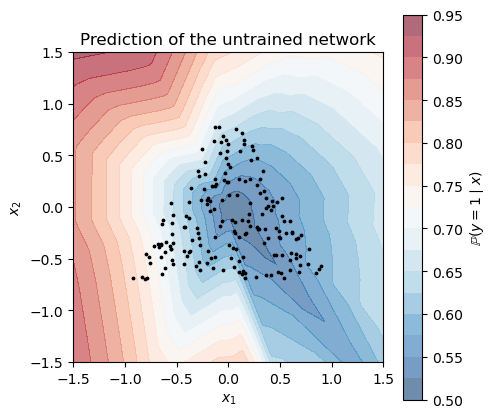

In [10]:
P_grid, _ = forward(params, grid)
plt.figure(figsize=(5, 5))
plt.contourf(xx1, xx2, P_grid[:, 1].reshape(xx1.shape), levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(label=r"$\mathbb{P}(y = 1 \mid x)$")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=3, c="k")
plt.title("Prediction of the untrained network")
plt.gca().set_aspect("equal")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

As expected, the untrained network has nothing to do with the triangle. Nevertheless, we now have everything we need to train it:

- a **model** $f_\Theta$ (the MLP), expressive enough to represent the triangle (we built one by hand!),
- a **loss function** $\mathcal{L}(\Theta)$ (the Cross-Entropy), measuring how wrong the network is,
- the **gradient** $\nabla_\Theta \mathcal{L}(\Theta)$, computed efficiently by backpropagation.

The only missing piece is the answer to the question:

> *How can we use the gradient to find the parameters $\Theta^*$ that minimize the loss?*

This is the topic of the next chapter, where we will introduce the **Gradient Descent** algorithm.

> **Exercise:** Modify the functions `forward` and `backward` to use the $\tanh$ activation function instead of the ReLU. Check the correctness of your implementation with the finite-difference test above.